## 下載

In [ ]:
!pip install imbalanced-learn

In [ ]:
# Colab 進行matplotlib繪圖時顯示繁體中文
# 下載台北思源黑體並命名taipei_sans_tc_beta.ttf，移至指定路徑
!wget -O TaipeiSansTCBeta-Regular.ttf https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download

import matplotlib

# 改style要在改font之前
# plt.style.use('seaborn')

matplotlib.font_manager.fontManager.addfont('TaipeiSansTCBeta-Regular.ttf')
matplotlib.rc('font', family='Taipei Sans TC Beta')

--2024-12-28 07:59:17--  https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.google.com (drive.google.com)... 142.251.175.101, 142.251.175.139, 142.251.175.102, ...
Connecting to drive.google.com (drive.google.com)|142.251.175.101|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_ [following]
--2024-12-28 07:59:18--  https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 64.233.170.132, 2404:6800:4003:c1a::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|64.233.170.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 20659344 (20M) [application/octet-stream]
Saving to: ‘TaipeiSansTCBeta-Regular.ttf’

TaipeiSansTCBeta-Re 100%[===================>]  19.70M  40.0MB/s    in 0.5s    

2024-12-28 07

# **前置**

## 連結雲端 & 套件

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 清理
from tqdm import tqdm
import re
from imblearn.over_sampling import SMOTE

# 圖
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 向量化
import nltk
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer
import warnings
warnings.filterwarnings('ignore')

from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords

from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder

# 模型
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

from sklearn.svm import SVC,LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier

from imblearn.over_sampling import SMOTE


[nltk_data] Downloading package wordnet to /root/nltk_data...


## 描述資料

In [3]:
data=pd.read_csv('/content/drive/MyDrive/mbti_1.csv')
data.head()

In [4]:
data.describe(include='O')

In [5]:
data['type'].value_counts()

,count
type,
INFP,1832
INFJ,1470
INTP,1304
INTJ,1091
ENTP,685
ENFP,675
ISTP,337
ISFP,271
ENTJ,231


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8675 entries, 0 to 8674
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   type    8675 non-null   object
 1   posts   8675 non-null   object
dtypes: object(2)
memory usage: 135.7+ KB


## 分割 ( train & test ) & 清整

In [7]:
train_data, test_data = train_test_split(data, test_size = 0.2, random_state = 16, stratify = data.type)

In [8]:
def clean(data):
    length = []
    lemmatizer = WordNetLemmatizer()
    cleaned = []
    for s in tqdm(data.posts):
        s = s.lower()
        s = re.sub('https?://[^\s<>"]+|www\.[^\s<>"]+', ' ', s)
        s = re.sub('[^0-9a-z]', ' ', s)
        length.append(len(s.split()))
        cleaned.append(s)
    return cleaned, length

In [9]:
train_data.posts, train_len = clean(train_data)

100%|██████████| 6940/6940 [00:05<00:00, 1258.70it/s]


In [10]:
test_data.posts, test_len = clean(test_data)

100%|██████████| 1735/1735 [00:01<00:00, 1729.59it/s]


In [11]:
# Colab 進行matplotlib繪圖時顯示繁體中文
# 下載台北思源黑體並命名taipei_sans_tc_beta.ttf，移至指定路徑
!wget -O TaipeiSansTCBeta-Regular.ttf https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download

import matplotlib

# 改style要在改font之前
# plt.style.use('seaborn')

matplotlib.font_manager.fontManager.addfont('TaipeiSansTCBeta-Regular.ttf')
matplotlib.rc('font', family='Taipei Sans TC Beta')

--2025-01-01 10:47:29--  https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.google.com (drive.google.com)... 74.125.130.138, 74.125.130.100, 74.125.130.101, ...
Connecting to drive.google.com (drive.google.com)|74.125.130.138|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_ [following]
--2025-01-01 10:47:29--  https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 142.251.175.132, 2404:6800:4003:c1c::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|142.251.175.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 20659344 (20M) [application/octet-stream]
Saving to: ‘TaipeiSansTCBeta-Regular.ttf’

TaipeiSansTCBeta-Re 100%[===================>]  19.70M  43.4MB/s    in 0.5s    

2025-01-01 10:4

## 圖

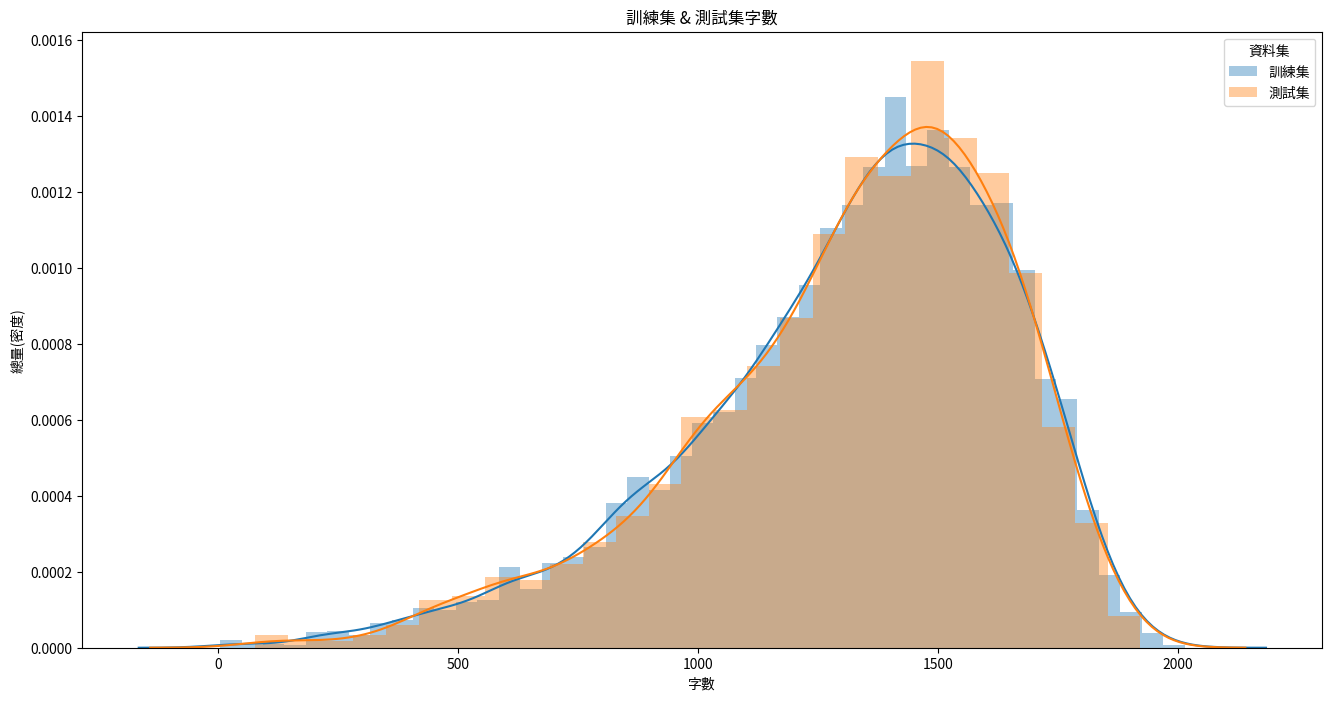

In [12]:
plt.figure(figsize = (16,8))
sns.distplot(train_len, label = '訓練集')
sns.distplot(test_len, label = '測試集')
plt.xlabel('字數')
plt.ylabel('總量(密度)')
plt.title('訓練集 & 測試集字數')
plt.legend(title='資料集')
plt.show()

In [13]:
px.pie(train_data, names = 'type', title = '各人格資料數')

## 向量化 & 特徵提取

In [14]:
# 還原字詞變成原型
class Lemmatizer(object):
    def __init__(self):
        self.lemmatizer = WordNetLemmatizer()
    def __call__(self, sentence):
        return [self.lemmatizer.lemmatize(word) for word in sentence.split() if len(word)>2]

In [15]:
vectorizer = TfidfVectorizer(max_features = 5000, stop_words = 'english', tokenizer = Lemmatizer())
vectorizer.fit(train_data.posts)

TfidfVectorizer(max_features=5000, stop_words='english',
                tokenizer=<__main__.Lemmatizer object at 0x7dd1fc6727a0>)

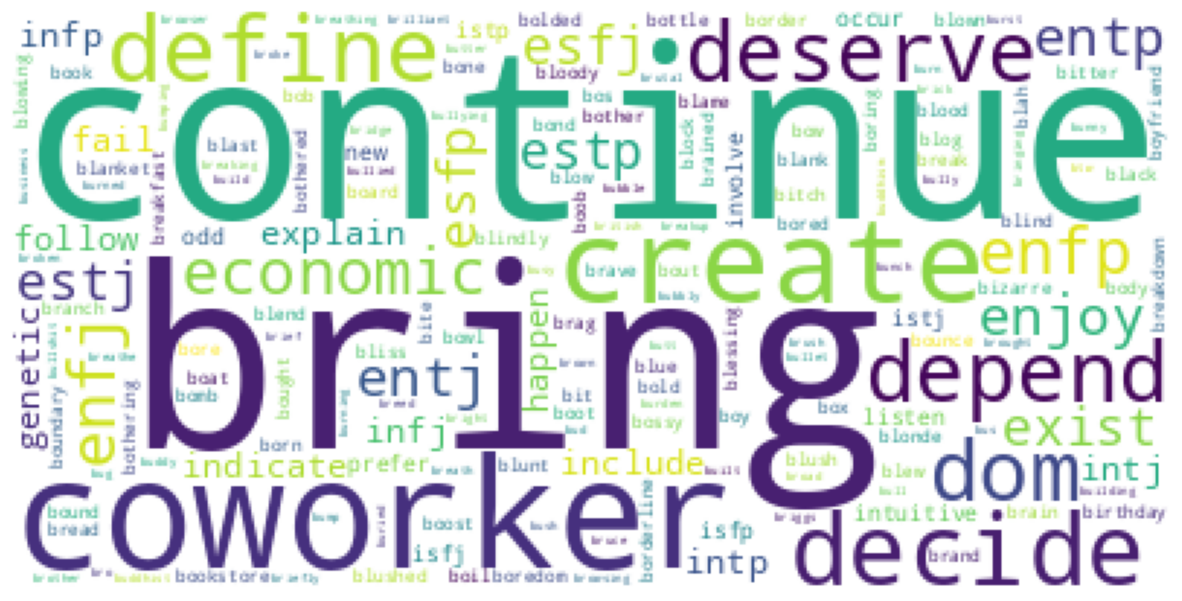

In [16]:
feature_names = vectorizer.get_feature_names_out()
wc = WordCloud(max_words = 400, background_color='white')
wc.generate(' '.join(word for word in feature_names[500:3500]))
plt.figure(figsize = (15, 10))
plt.axis('off')
plt.imshow(wc)

In [17]:
train_post = vectorizer.transform(train_data.posts).toarray()
test_post = vectorizer.transform(test_data.posts).toarray()

In [18]:
train_post.shape

(6940, 5000)

In [19]:
# 類別轉數值
target_encoder = LabelEncoder()
train_target = target_encoder.fit_transform(train_data.type)
test_target = target_encoder.fit_transform(test_data.type)

# **測試 1**

## 不同模型的訓練 & 測試

In [ ]:
models_accuracy = {}

### Logistic Regression

*   `max_iter` 影響模型的訓練時間和收斂速度。
*   `C` 控制正則化強度，影響過擬合與欠擬合。
*   `n_jobs` 影響訓練過程中的運算效能，能加速訓練。








In [ ]:
log = LogisticRegression(max_iter = 100, C = 1.0, n_jobs = 1)
log.fit(train_post, train_target)

LogisticRegression(n_jobs=1)

In [ ]:
print('訓練結果:\n', classification_report(train_target, log.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, log.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.84      0.32      0.47       152
        ENFP       0.83      0.74      0.78       540
        ENTJ       0.91      0.46      0.61       185
        ENTP       0.83      0.77      0.80       548
        ESFJ       1.00      0.09      0.17        33
        ESFP       0.00      0.00      0.00        38
        ESTJ       0.00      0.00      0.00        31
        ESTP       0.84      0.23      0.36        71
        INFJ       0.80      0.87      0.83      1176
        INFP       0.75      0.93      0.83      1466
        INTJ       0.78      0.85      0.81       873
        INTP       0.78      0.90      0.83      1043
        ISFJ       0.89      0.43      0.58       133
        ISFP       0.90      0.48      0.63       217
        ISTJ       0.87      0.49      0.62       164
        ISTP       0.88      0.73      0.80       270

    accuracy                           0.79      6940
   macro avg       

In [ ]:
models_accuracy['logistic regression'] = accuracy_score(test_target, log.predict(test_post))

### Linear Support Vector classifier

**`C`**：
   - **意思**: `C` 是正則化參數，用來控制模型的正則化強度。`C` 值越小，正則化強度越大，模型會強制使得決策邊界盡量平滑，避免過度擬合訓練資料。
   - **影響**: 較強的正則化，會讓模型對資料中的噪音和異常點更加不敏感，從而可能降低過擬合的風險。但是，如果 `C` 太小，可能會導致模型欠擬合，即無法充分擬合訓練資料，表現較差。

`LinearSVC` 的其他參數（預設）：
- **`max_iter`**：預設值為 `1000`，指定模型訓練的最大迭代次數。如果模型在這個數量的迭代次數內未收斂，可以調整這個參數。
- **`loss`**：預設是 `'squared_hinge'`，表示使用平方的合頁損失函數（這是 SVM 的標準損失函數之一）。
- **`penalty`**：預設是 `'l2'`，表示使用 L2 正則化，即權重的平方和懲罰，這有助於防止過擬合。

In [ ]:
linearsvc = LinearSVC(C = 1.0)
linearsvc.fit(train_post, train_target)

LinearSVC()

In [ ]:
print('訓練結果:\n', classification_report(train_target, linearsvc.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, linearsvc.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.99      0.96      0.97       152
        ENFP       0.98      0.97      0.97       540
        ENTJ       1.00      0.97      0.99       185
        ENTP       0.98      0.98      0.98       548
        ESFJ       1.00      0.97      0.98        33
        ESFP       1.00      0.92      0.96        38
        ESTJ       1.00      0.94      0.97        31
        ESTP       1.00      0.99      0.99        71
        INFJ       0.97      0.98      0.98      1176
        INFP       0.97      0.99      0.98      1466
        INTJ       0.98      0.97      0.98       873
        INTP       0.98      0.99      0.98      1043
        ISFJ       0.99      0.98      0.99       133
        ISFP       0.99      0.97      0.98       217
        ISTJ       0.99      0.99      0.99       164
        ISTP       0.99      0.99      0.99       270

    accuracy                           0.98      6940
   macro avg       

In [ ]:
models_accuracy['Linear Support Vector classifier'] = accuracy_score(test_target, linearsvc.predict(test_post))

### Support Vector classifier

In [ ]:
svc = SVC()
svc.fit(train_post, train_target)

SVC()

In [ ]:
print('訓練結果:\n', classification_report(train_target, svc.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, svc.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.98      0.85      0.91       152
        ENFP       0.96      0.95      0.95       540
        ENTJ       0.98      0.89      0.93       185
        ENTP       0.95      0.95      0.95       548
        ESFJ       1.00      0.55      0.71        33
        ESFP       1.00      0.32      0.48        38
        ESTJ       1.00      0.65      0.78        31
        ESTP       0.98      0.86      0.92        71
        INFJ       0.95      0.97      0.96      1176
        INFP       0.93      0.98      0.96      1466
        INTJ       0.96      0.96      0.96       873
        INTP       0.95      0.98      0.96      1043
        ISFJ       0.99      0.90      0.94       133
        ISFP       0.96      0.88      0.92       217
        ISTJ       0.95      0.91      0.93       164
        ISTP       0.97      0.95      0.96       270

    accuracy                           0.95      6940
   macro avg       

In [ ]:
models_accuracy['Support Vector classifier'] = accuracy_score(test_target, svc.predict(test_post))

### Decision Tree Classifier

**`max_depth`**：
   - **意思**: `max_depth` 參數限制了決策樹的最大深度。決策樹的深度是指從根節點到最遠葉節點的最大層數。這個參數用來控制樹的大小和複雜度。
   - **影響**:
     - 增加 `max_depth` 會讓樹變得更深，能夠擬合更多的細節和複雜模式，但也可能導致過擬合，尤其是在訓練資料噪音較大時。
     - 減少 `max_depth` 會讓樹變得較淺，減少過擬合的風險，但也可能會導致欠擬合，即無法捕捉到資料的複雜模式。
     在隨機森林（Random Forest）模型中，`max_depth` 的設定通常取決於資料的特性和模型的複雜度。不同於單一的決策樹，隨機森林由多個決策樹組成，每棵樹都會根據資料隨機選擇特徵進行訓練，因此在隨機森林中 `max_depth` 的設定通常較為寬鬆。

1. **`max_depth` 預設值**：
   - 在 `RandomForestClassifier` 中，`max_depth` 的預設值是 **`None`**。這表示每棵樹會一直生長，直到達到停止條件（如每個葉節點的樣本數量小於 `min_samples_split`）。
   - 類似於決策樹，預設為 `None` 可能會導致每棵樹過度擬合，尤其是當資料集包含大量特徵或樣本時。

2. **常見的 `max_depth` 設定**：
   - **`max_depth` 一般設定範圍**：常見的 `max_depth` 設定值範圍大約在 **`5` 到 `20`** 之間，這取決於資料的複雜度。較大的 `max_depth` 值可以讓每棵樹擁有更多的分割點，有助於捕捉複雜的模式，但也可能會增加過擬合的風險。
   - **較小的 `max_depth`**（例如 `5` 到 `10`）：有助於防止每棵樹過度擬合，並提高模型的泛化能力。這通常適用於特徵較少或資料較簡單的情況。
   - **較大的 `max_depth`**（例如 `15` 到 `20`）：當資料集較為複雜且特徵較多時，可以適當增加 `max_depth` 來讓模型更好地擬合資料，這樣可以捕捉更多的資料模式。

3. **選擇 `max_depth` 的策略**：
   - **交叉驗證**：選擇最佳的 `max_depth` 通常需要透過交叉驗證來調整。使用交叉驗證來評估不同 `max_depth` 值對模型效能的影響，選擇能夠最大化測試集準確度的值。
   - **避免過擬合**：過大的 `max_depth` 會讓每棵樹過於擬合訓練數據，降低模型的泛化能力。調整 `max_depth` 可以幫助平衡模型的擬合能力與其對新數據的預測能力。

其他常見參數的預設值：
- **`criterion`**：預設為 `'gini'`，表示使用 Gini 指數來衡量資料的純度。如果使用 `'entropy'`，則會使用資訊增益來進行分裂。
- **`splitter`**：預設為 `'best'`，表示在每一層中選擇最佳的分割方式。還可以選擇 `'random'`，在每層隨機選擇分割方式。
- **`max_features`**：預設為 `None`，表示對每個分割節點考慮所有特徵。如果設為一個具體值（如整數或浮點數），則會限制每個節點分裂時可以考慮的特徵數量。
- **`min_samples_split`**：預設為 `2`，表示最少需要多少個樣本才能進行節點的分裂。


In [ ]:
decisiontree = DecisionTreeClassifier(max_depth = 15)
decisiontree.fit(train_post, train_target)

DecisionTreeClassifier(max_depth=15)

In [ ]:
print('訓練結果:\n', classification_report(train_target, decisiontree.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, decisiontree.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.83      0.62      0.71       152
        ENFP       0.92      0.84      0.88       540
        ENTJ       0.89      0.76      0.82       185
        ENTP       0.95      0.78      0.85       548
        ESFJ       0.67      0.48      0.56        33
        ESFP       0.94      0.45      0.61        38
        ESTJ       1.00      0.52      0.68        31
        ESTP       0.88      0.49      0.63        71
        INFJ       0.87      0.85      0.86      1176
        INFP       0.66      0.95      0.78      1466
        INTJ       0.90      0.81      0.86       873
        INTP       0.87      0.84      0.86      1043
        ISFJ       0.95      0.67      0.78       133
        ISFP       0.98      0.70      0.81       217
        ISTJ       0.83      0.70      0.76       164
        ISTP       0.95      0.74      0.83       270

    accuracy                           0.83      6940
   macro avg       

In [ ]:
models_accuracy['Decision Tree classifier'] = accuracy_score(test_target, decisiontree.predict(test_post))

### Random Forest Classifier

In [ ]:
randomforest = RandomForestClassifier(max_depth = 15)
randomforest.fit(train_post, train_target)

RandomForestClassifier(max_depth=15)

In [ ]:
print('訓練結果:\n', classification_report(train_target, randomforest.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, randomforest.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      0.40      0.57       152
        ENFP       1.00      0.84      0.91       540
        ENTJ       1.00      0.59      0.74       185
        ENTP       1.00      0.88      0.94       548
        ESFJ       1.00      0.09      0.17        33
        ESFP       1.00      0.18      0.31        38
        ESTJ       1.00      0.19      0.32        31
        ESTP       1.00      0.34      0.51        71
        INFJ       0.91      0.97      0.94      1176
        INFP       0.71      1.00      0.83      1466
        INTJ       0.95      0.96      0.95       873
        INTP       0.88      0.98      0.93      1043
        ISFJ       1.00      0.36      0.53       133
        ISFP       1.00      0.51      0.68       217
        ISTJ       1.00      0.48      0.65       164
        ISTP       1.00      0.75      0.86       270

    accuracy                           0.87      6940
   macro avg       

In [ ]:
models_accuracy['Random Forest Classifier'] = accuracy_score(test_target, randomforest.predict(test_post))

### XGBoost Classifier

1. **`gpu_id`**
   - **功能**：指定 GPU 編號，用於加速運算。
   - **預設值**：`-1`（不使用 GPU）。
   - **範例**：`gpu_id=0` 表示使用第一塊 GPU。



2. **`tree_method`**
   - **功能**：指定構建決策樹的算法。  
     - `gpu_hist` 是針對 GPU 加速的直方圖算法，適合大規模數據。
     - 其他選項包括 `auto`, `exact`, `approx`, `hist` 等。
   - **預設值**：`auto`（會根據數據大小自動選擇適合的算法）。



3. **`max_depth`**
   - **功能**：決定每棵樹的最大深度。  
     控制樹的複雜度，防止過擬合。
   - **預設值**：`6`。



4. **`n_estimators`**
   - **功能**：指定要生成的弱分類器（決策樹）的數量。
   - **預設值**：`100`。



5. **`learning_rate`**
   - **功能**：學習率，控制每次樹的貢獻權重。  
     較小的學習率需要更多的樹（`n_estimators`），但通常會提高模型的表現。
   - **預設值**：`0.3`。
   - **範例**：`learning_rate=0.1` 表示降低每次更新的影響。


6. **`fit` 函數**
   - **功能**：訓練模型。
   - **主要參數**：
     - `X`: 訓練數據特徵。
     - `y`: 訓練數據的目標標籤。
     - **其他常用參數**：
       - `eval_set`: 提供測試數據來進行早停。
       - `early_stopping_rounds`: 設定早停的回合數。
       - `verbose`: 控制訓練過程的輸出，`True` 會顯示細節。
   - **範例**：`xgb.fit(train_post, train_target)`。


In [ ]:
xgb = XGBClassifier(max_depth = 6, n_estimators = 100, learning_rate = 0.3)
xgb.fit(train_post, train_target)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.3, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [ ]:
print('訓練結果:\n', classification_report(train_target, xgb.predict(train_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, xgb.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00       152
        ENFP       1.00      1.00      1.00       540
        ENTJ       1.00      1.00      1.00       185
        ENTP       1.00      1.00      1.00       548
        ESFJ       1.00      1.00      1.00        33
        ESFP       1.00      1.00      1.00        38
        ESTJ       1.00      1.00      1.00        31
        ESTP       1.00      1.00      1.00        71
        INFJ       1.00      1.00      1.00      1176
        INFP       1.00      1.00      1.00      1466
        INTJ       1.00      1.00      1.00       873
        INTP       1.00      1.00      1.00      1043
        ISFJ       1.00      1.00      1.00       133
        ISFP       1.00      1.00      1.00       217
        ISTJ       1.00      1.00      1.00       164
        ISTP       1.00      1.00      1.00       270

    accuracy                           1.00      6940
   macro avg       

In [ ]:
models_accuracy['XGBoost Classifier'] = accuracy_score(test_target, xgb.predict(test_post))

## 結果評估

In [ ]:
models_accuracy

{'logistic regression': 0.6426512968299711,
 'Linear Support Vector classifier': 0.6386167146974063,
 'Support Vector classifier': 0.6397694524495677,
 'Decision Tree classifier': 0.5020172910662825,
 'Random Forest Classifier': 0.48703170028818443,
 'XGBoost Classifier': 0.6853025936599424}

In [ ]:
models_accuracy.keys()

dict_keys(['logistic regression', 'Linear Support Vector classifier', 'Support Vector classifier', 'Decision Tree classifier', 'Random Forest Classifier', 'XGBoost Classifier'])

In [ ]:
accuarcy = pd.DataFrame(models_accuracy.items(), columns = ['模型', '測試準確率'])

In [ ]:
accuarcy.sort_values(by = '測試準確率', ascending = False, ignore_index = True).style.background_gradient(cmap = 'Blues')

,模型,測試準確率
0,XGBoost Classifier,0.685303
1,logistic regression,0.642651
2,Support Vector classifier,0.639769
3,Linear Support Vector classifier,0.638617
4,Decision Tree classifier,0.502017
5,Random Forest Classifier,0.487032


# **測試 2 加上SMOTE**

In [ ]:
# 初始化 SMOTE
smote = SMOTE(random_state=42)

# 使用 SMOTE 平衡訓練數據
train_post_smote, train_target_smote = smote.fit_resample(train_post, train_target)

# 檢查平衡後的類別分布
print("Before SMOTE:", dict(pd.Series(train_target).value_counts()))
print("After SMOTE:", dict(pd.Series(train_target_smote).value_counts()))

Before SMOTE: {9: 1466, 8: 1176, 11: 1043, 10: 873, 3: 548, 1: 540, 15: 270, 13: 217, 2: 185, 14: 164, 0: 152, 12: 133, 7: 71, 5: 38, 4: 33, 6: 31}
After SMOTE: {3: 1466, 9: 1466, 8: 1466, 1: 1466, 10: 1466, 11: 1466, 5: 1466, 12: 1466, 13: 1466, 15: 1466, 2: 1466, 0: 1466, 14: 1466, 6: 1466, 4: 1466, 7: 1466}


## 不同模型的訓練 & 測試

In [ ]:
models_accuracy = {}

### Logistic Regression

*   `max_iter` 影響模型的訓練時間和收斂速度。
*   `C` 控制正則化強度，影響過擬合與欠擬合。
*   `n_jobs` 影響訓練過程中的運算效能，能加速訓練。








In [ ]:
log = LogisticRegression(max_iter = 100, C = 1.0, n_jobs = 1)
log.fit(train_post_smote, train_target_smote)

LogisticRegression(n_jobs=1)

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, log.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, log.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.97      0.98      0.98      1466
        ENFP       0.94      0.90      0.92      1466
        ENTJ       0.97      0.97      0.97      1466
        ENTP       0.93      0.92      0.93      1466
        ESFJ       0.99      1.00      1.00      1466
        ESFP       0.99      1.00      0.99      1466
        ESTJ       0.99      1.00      1.00      1466
        ESTP       0.99      1.00      0.99      1466
        INFJ       0.90      0.86      0.88      1466
        INFP       0.88      0.88      0.88      1466
        INTJ       0.90      0.90      0.90      1466
        INTP       0.91      0.90      0.91      1466
        ISFJ       0.98      0.99      0.99      1466
        ISFP       0.97      0.97      0.97      1466
        ISTJ       0.98      0.99      0.99      1466
        ISTP       0.96      0.98      0.97      1466

    accuracy                           0.95     23456
   macro avg       

In [ ]:
models_accuracy['logistic regression'] = accuracy_score(test_target, log.predict(test_post))

### Linear Support Vector classifier

**`C`**：
   - **意思**: `C` 是正則化參數，用來控制模型的正則化強度。`C` 值越小，正則化強度越大，模型會強制使得決策邊界盡量平滑，避免過度擬合訓練資料。
   - **影響**: 較強的正則化，會讓模型對資料中的噪音和異常點更加不敏感，從而可能降低過擬合的風險。但是，如果 `C` 太小，可能會導致模型欠擬合，即無法充分擬合訓練資料，表現較差。

`LinearSVC` 的其他參數（預設）：
- **`max_iter`**：預設值為 `1000`，指定模型訓練的最大迭代次數。如果模型在這個數量的迭代次數內未收斂，可以調整這個參數。
- **`loss`**：預設是 `'squared_hinge'`，表示使用平方的合頁損失函數（這是 SVM 的標準損失函數之一）。
- **`penalty`**：預設是 `'l2'`，表示使用 L2 正則化，即權重的平方和懲罰，這有助於防止過擬合。

In [ ]:
linearsvc = LinearSVC(C = 1.0)
linearsvc.fit(train_post_smote, train_target_smote)

LinearSVC()

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, linearsvc.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, linearsvc.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       0.99      1.00      0.99      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       0.99      0.99      0.99      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       0.99      0.98      0.98      1466
        INFP       0.99      0.98      0.98      1466
        INTJ       0.99      0.98      0.99      1466
        INTP       0.99      0.99      0.99      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
models_accuracy['Linear Support Vector classifier'] = accuracy_score(test_target, linearsvc.predict(test_post))

### Support Vector classifier

In [ ]:
svc = SVC()
svc.fit(train_post_smote, train_target_smote)

SVC()

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, svc.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, svc.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       1.00      1.00      1.00      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       1.00      1.00      1.00      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       0.99      0.99      0.99      1466
        INFP       0.99      0.98      0.99      1466
        INTJ       0.99      0.99      0.99      1466
        INTP       1.00      0.99      0.99      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
models_accuracy['Support Vector classifier'] = accuracy_score(test_target, svc.predict(test_post))

### Decision Tree Classifier

**`max_depth`**：
   - **意思**: `max_depth` 參數限制了決策樹的最大深度。決策樹的深度是指從根節點到最遠葉節點的最大層數。這個參數用來控制樹的大小和複雜度。
   - **影響**:
     - 增加 `max_depth` 會讓樹變得更深，能夠擬合更多的細節和複雜模式，但也可能導致過擬合，尤其是在訓練資料噪音較大時。
     - 減少 `max_depth` 會讓樹變得較淺，減少過擬合的風險，但也可能會導致欠擬合，即無法捕捉到資料的複雜模式。
     在隨機森林（Random Forest）模型中，`max_depth` 的設定通常取決於資料的特性和模型的複雜度。不同於單一的決策樹，隨機森林由多個決策樹組成，每棵樹都會根據資料隨機選擇特徵進行訓練，因此在隨機森林中 `max_depth` 的設定通常較為寬鬆。

1. **`max_depth` 預設值**：
   - 在 `RandomForestClassifier` 中，`max_depth` 的預設值是 **`None`**。這表示每棵樹會一直生長，直到達到停止條件（如每個葉節點的樣本數量小於 `min_samples_split`）。
   - 類似於決策樹，預設為 `None` 可能會導致每棵樹過度擬合，尤其是當資料集包含大量特徵或樣本時。

2. **常見的 `max_depth` 設定**：
   - **`max_depth` 一般設定範圍**：常見的 `max_depth` 設定值範圍大約在 **`5` 到 `20`** 之間，這取決於資料的複雜度。較大的 `max_depth` 值可以讓每棵樹擁有更多的分割點，有助於捕捉複雜的模式，但也可能會增加過擬合的風險。
   - **較小的 `max_depth`**（例如 `5` 到 `10`）：有助於防止每棵樹過度擬合，並提高模型的泛化能力。這通常適用於特徵較少或資料較簡單的情況。
   - **較大的 `max_depth`**（例如 `15` 到 `20`）：當資料集較為複雜且特徵較多時，可以適當增加 `max_depth` 來讓模型更好地擬合資料，這樣可以捕捉更多的資料模式。

3. **選擇 `max_depth` 的策略**：
   - **交叉驗證**：選擇最佳的 `max_depth` 通常需要透過交叉驗證來調整。使用交叉驗證來評估不同 `max_depth` 值對模型效能的影響，選擇能夠最大化測試集準確度的值。
   - **避免過擬合**：過大的 `max_depth` 會讓每棵樹過於擬合訓練數據，降低模型的泛化能力。調整 `max_depth` 可以幫助平衡模型的擬合能力與其對新數據的預測能力。

其他常見參數的預設值：
- **`criterion`**：預設為 `'gini'`，表示使用 Gini 指數來衡量資料的純度。如果使用 `'entropy'`，則會使用資訊增益來進行分裂。
- **`splitter`**：預設為 `'best'`，表示在每一層中選擇最佳的分割方式。還可以選擇 `'random'`，在每層隨機選擇分割方式。
- **`max_features`**：預設為 `None`，表示對每個分割節點考慮所有特徵。如果設為一個具體值（如整數或浮點數），則會限制每個節點分裂時可以考慮的特徵數量。
- **`min_samples_split`**：預設為 `2`，表示最少需要多少個樣本才能進行節點的分裂。


In [ ]:
decisiontree = DecisionTreeClassifier(max_depth = 15)
decisiontree.fit(train_post_smote, train_target_smote)

DecisionTreeClassifier(max_depth=15)

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, decisiontree.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, decisiontree.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.92      0.70      0.79      1466
        ENFP       0.79      0.72      0.76      1466
        ENTJ       0.94      0.73      0.82      1466
        ENTP       0.82      0.67      0.74      1466
        ESFJ       1.00      0.86      0.92      1466
        ESFP       0.97      0.74      0.84      1466
        ESTJ       1.00      0.84      0.91      1466
        ESTP       0.95      0.82      0.88      1466
        INFJ       0.58      0.58      0.58      1466
        INFP       0.20      0.70      0.31      1466
        INTJ       0.59      0.57      0.58      1466
        INTP       0.60      0.58      0.59      1466
        ISFJ       0.98      0.74      0.85      1466
        ISFP       0.94      0.68      0.79      1466
        ISTJ       0.93      0.66      0.77      1466
        ISTP       0.89      0.73      0.80      1466

    accuracy                           0.71     23456
   macro avg       

In [ ]:
models_accuracy['Decision Tree classifier'] = accuracy_score(test_target, decisiontree.predict(test_post))

### Random Forest Classifier

In [ ]:
randomforest = RandomForestClassifier(max_depth = 15)
randomforest.fit(train_post_smote, train_target_smote)

RandomForestClassifier(max_depth=15)

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, randomforest.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, randomforest.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       0.99      0.98      0.99      1466
        ENFP       0.99      0.94      0.96      1466
        ENTJ       0.99      0.99      0.99      1466
        ENTP       0.97      0.94      0.96      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      0.99      0.99      1466
        INFJ       0.95      0.92      0.93      1466
        INFP       0.80      0.97      0.88      1466
        INTJ       0.96      0.92      0.94      1466
        INTP       0.91      0.94      0.93      1466
        ISFJ       1.00      0.99      0.99      1466
        ISFP       1.00      0.97      0.98      1466
        ISTJ       1.00      0.98      0.99      1466
        ISTP       0.99      0.98      0.98      1466

    accuracy                           0.97     23456
   macro avg       

In [ ]:
models_accuracy['Random Forest Classifier'] = accuracy_score(test_target, randomforest.predict(test_post))

### XGBoost Classifier

1. **`gpu_id`**
   - **功能**：指定 GPU 編號，用於加速運算。
   - **預設值**：`-1`（不使用 GPU）。
   - **範例**：`gpu_id=0` 表示使用第一塊 GPU。



2. **`tree_method`**
   - **功能**：指定構建決策樹的算法。  
     - `gpu_hist` 是針對 GPU 加速的直方圖算法，適合大規模數據。
     - 其他選項包括 `auto`, `exact`, `approx`, `hist` 等。
   - **預設值**：`auto`（會根據數據大小自動選擇適合的算法）。



3. **`max_depth`**
   - **功能**：決定每棵樹的最大深度。  
     控制樹的複雜度，防止過擬合。
   - **預設值**：`6`。



4. **`n_estimators`**
   - **功能**：指定要生成的弱分類器（決策樹）的數量。
   - **預設值**：`100`。



5. **`learning_rate`**
   - **功能**：學習率，控制每次樹的貢獻權重。  
     較小的學習率需要更多的樹（`n_estimators`），但通常會提高模型的表現。
   - **預設值**：`0.3`。
   - **範例**：`learning_rate=0.1` 表示降低每次更新的影響。


6. **`fit` 函數**
   - **功能**：訓練模型。
   - **主要參數**：
     - `X`: 訓練數據特徵。
     - `y`: 訓練數據的目標標籤。
     - **其他常用參數**：
       - `eval_set`: 提供測試數據來進行早停。
       - `early_stopping_rounds`: 設定早停的回合數。
       - `verbose`: 控制訓練過程的輸出，`True` 會顯示細節。
   - **範例**：`xgb.fit(train_post, train_target)`。


In [ ]:
xgb = XGBClassifier(max_depth = 6, n_estimators = 100, learning_rate = 0.3)
xgb.fit(train_post_smote, train_target_smote)

In [ ]:
print('訓練結果:\n', classification_report(train_target_smote, xgb.predict(train_post_smote), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, xgb.predict(test_post), target_names = target_encoder.inverse_transform([i for i in range(16)])))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       1.00      1.00      1.00      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       1.00      1.00      1.00      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       1.00      1.00      1.00      1466
        INFP       1.00      1.00      1.00      1466
        INTJ       1.00      1.00      1.00      1466
        INTP       1.00      1.00      1.00      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
models_accuracy['XGBoost Classifier'] = accuracy_score(test_target, xgb.predict(test_post))

## 結果評估

In [ ]:
models_accuracy

{'logistic regression': 0.6910662824207493,
 'Linear Support Vector classifier': 0.624207492795389,
 'Support Vector classifier': 0.6426512968299711,
 'Decision Tree classifier': 0.47089337175792506,
 'Random Forest Classifier': 0.6184438040345821,
 'XGBoost Classifier': 0.6685878962536023}

In [ ]:
models_accuracy.keys()

dict_keys(['logistic regression', 'Linear Support Vector classifier', 'Support Vector classifier', 'Decision Tree classifier', 'Random Forest Classifier', 'XGBoost Classifier'])

In [ ]:
accuarcy = pd.DataFrame(models_accuracy.items(), columns = ['模型', '測試準確率'])

In [ ]:
accuarcy.sort_values(by = '測試準確率', ascending = False, ignore_index = True).style.background_gradient(cmap = 'Blues')

,模型,測試準確率
0,logistic regression,0.691066
1,XGBoost Classifier,0.668588
2,Support Vector classifier,0.642651
3,Linear Support Vector classifier,0.624207
4,Random Forest Classifier,0.618444
5,Decision Tree classifier,0.470893


# **測試 3 參數修改**

## 修改參數

In [ ]:
models_accuracy2 = {}

### **Log 不同於第一次測試的部分：**

1. 在訓練之前對特徵進行標準化處理（例如用 StandardScaler）
2. 調整正則化參數 C
3. 更換正則化方式 l2 -> l1（可以產生稀疏解）



In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train_post_scaled = scaler.fit_transform(train_post_smote)
test_post_scaled = scaler.transform(test_post)

In [ ]:
# Logistic Regression
log = LogisticRegression(penalty = 'l1', solver = 'liblinear', max_iter = 100, C = 0.1)
log.fit(train_post_scaled, train_target_smote)

print('訓練結果:\n', classification_report(train_target_smote, log.predict(train_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, log.predict(test_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))

models_accuracy2['logistic regression'] = accuracy_score(test_target, log.predict(test_post_scaled))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       1.00      1.00      1.00      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       1.00      1.00      1.00      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       1.00      1.00      1.00      1466
        INFP       1.00      1.00      1.00      1466
        INTJ       1.00      1.00      1.00      1466
        INTP       1.00      1.00      1.00      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
accuracy_score(test_target, log.predict(test_post_scaled))

0.5809798270893372

### **SVC 不同於第一次測試的部分：**

為了知道最適合的參數設定，嘗試不同的核函數、懲罰參數和 gamma， 最終確認參數

Best params: {'C': 1, 'gamma': 0.01, 'kernel': 'linear'}

In [ ]:
# Support Vector classifier
from sklearn.model_selection import GridSearchCV
#param_grid = {
#    'C': [0.1, 1, 10],
#    'gamma': [0.01, 0.1, 1],
#    'kernel': ['rbf', 'poly', 'linear']
#}
#grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
#grid_search.fit(train_post_scaled, train_target_smote)
#print("Best params:", grid_search.best_params_)

In [ ]:
svc = SVC(C = 1, gamma = 0.01, kernel = 'linear')
svc.fit(train_post_scaled, train_target_smote)

print('訓練結果:\n', classification_report(train_target_smote, svc.predict(train_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, svc.predict(test_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))

models_accuracy2['Support Vector classifier'] = accuracy_score(test_target, svc.predict(test_post_scaled))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       1.00      1.00      1.00      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       1.00      1.00      1.00      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       1.00      1.00      1.00      1466
        INFP       1.00      1.00      1.00      1466
        INTJ       1.00      1.00      1.00      1466
        INTP       1.00      1.00      1.00      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
accuracy_score(test_target, svc.predict(test_post_scaled))

0.47780979827089337

### **LSVC 不同於第一次測試的部分：**

1. 調整正則化參數 C

In [ ]:
# Linear Support Vector classifier

linearsvc = LinearSVC(C = 0.1)
linearsvc.fit(train_post_scaled, train_target_smote)

print('訓練結果:\n', classification_report(train_target_smote, linearsvc.predict(train_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))
print('測試結果:\n', classification_report(test_target, linearsvc.predict(test_post_scaled), target_names = target_encoder.inverse_transform([i for i in range(16)])))

models_accuracy2['Linear Support Vector classifier'] = accuracy_score(test_target, linearsvc.predict(test_post_scaled))

訓練結果:
               precision    recall  f1-score   support

        ENFJ       1.00      1.00      1.00      1466
        ENFP       1.00      1.00      1.00      1466
        ENTJ       1.00      1.00      1.00      1466
        ENTP       1.00      1.00      1.00      1466
        ESFJ       1.00      1.00      1.00      1466
        ESFP       1.00      1.00      1.00      1466
        ESTJ       1.00      1.00      1.00      1466
        ESTP       1.00      1.00      1.00      1466
        INFJ       1.00      1.00      1.00      1466
        INFP       1.00      1.00      1.00      1466
        INTJ       1.00      1.00      1.00      1466
        INTP       1.00      1.00      1.00      1466
        ISFJ       1.00      1.00      1.00      1466
        ISFP       1.00      1.00      1.00      1466
        ISTJ       1.00      1.00      1.00      1466
        ISTP       1.00      1.00      1.00      1466

    accuracy                           1.00     23456
   macro avg       

In [ ]:
accuracy_score(test_target, linearsvc.predict(test_post_scaled))

0.3867435158501441

### **XGBoost調整**

1. 調整 max_depth 和 min_child_weight

  max_depth 控制樹的最大深度，min_child_weight 控制每個葉子節點所需的最小樣本權重總和。

  ```max_depth=8, min_child_weight=5```

2. 調整 learning_rate 和 n_estimators
  
  減小學習率（learning_rate）並增加樹的數量（n_estimators），提高模型的穩定性和泛化能力。

In [ ]:
best_xgb = XGBClassifier(max_depth=8, min_child_weight=5, learning_rate=0.1, n_estimators=200, reg_alpha=0.1, reg_lambda=10, random_state=42)
best_xgb.fit(train_post_smote, train_target_smote)

# 測試結果
from sklearn.metrics import classification_report, accuracy_score

y_pred = best_xgb.predict(test_post)
print("Accuracy:", accuracy_score(test_target, y_pred))
print('測試結果:\n', classification_report(test_target, y_pred, target_names = target_encoder.inverse_transform([i for i in range(16)])))
models_accuracy2['XGBoost Classifier'] = accuracy_score(test_target, y_pred)

Accuracy: 0.6864553314121038
測試結果:
               precision    recall  f1-score   support

        ENFJ       0.62      0.47      0.54        38
        ENFP       0.70      0.64      0.67       135
        ENTJ       0.77      0.52      0.62        46
        ENTP       0.62      0.63      0.63       137
        ESFJ       0.50      0.33      0.40         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.50      0.33      0.40        18
        INFJ       0.66      0.73      0.69       294
        INFP       0.75      0.73      0.74       366
        INTJ       0.69      0.68      0.68       218
        INTP       0.70      0.79      0.74       261
        ISFJ       0.73      0.67      0.70        33
        ISFP       0.60      0.65      0.62        54
        ISTJ       0.64      0.66      0.65        41
        ISTP       0.74      0.67      0.70        67

    accuracy                           0.69 

In [ ]:
accuracy_score(test_target, y_pred)

0.6864553314121038

### **XGBoost 正則化**

In [ ]:
best_xgb = XGBClassifier(max_depth=8, min_child_weight=5, learning_rate=0.1, n_estimators=200, reg_alpha=0.1, reg_lambda=10, random_state=42)
best_xgb.fit(train_post_scaled, train_target_smote)

# 測試結果
from sklearn.metrics import classification_report, accuracy_score

y_pred = best_xgb.predict(test_post_scaled)
print("Accuracy:", accuracy_score(test_target, y_pred))
print('測試結果:\n', classification_report(test_target, y_pred, target_names = target_encoder.inverse_transform([i for i in range(16)])))
models_accuracy2['XGBoost Classifier scaled'] = accuracy_score(test_target, y_pred)

Accuracy: 0.6858789625360231
測試結果:
               precision    recall  f1-score   support

        ENFJ       0.64      0.47      0.55        38
        ENFP       0.71      0.66      0.68       135
        ENTJ       0.77      0.52      0.62        46
        ENTP       0.62      0.63      0.63       137
        ESFJ       0.50      0.33      0.40         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.50      0.33      0.40        18
        INFJ       0.66      0.73      0.69       294
        INFP       0.74      0.74      0.74       366
        INTJ       0.67      0.67      0.67       218
        INTP       0.69      0.78      0.73       261
        ISFJ       0.72      0.64      0.68        33
        ISFP       0.63      0.67      0.65        54
        ISTJ       0.65      0.63      0.64        41
        ISTP       0.74      0.67      0.70        67

    accuracy                           0.69 

NameError: name 'models_accuracy2' is not defined

In [ ]:
accuracy_score(test_target, y_pred)

## 結果評估

In [ ]:
models_accuracy2 = {'logistic regression': 0.5809798270893372,
 'Linear Support Vector classifier': 0.3867435158501441,
 'Support Vector classifier': 0.47780979827089337,
 'XGBoost Classifier': 0.6864553314121038,
 'XGBoost Classifier scaled': 0.6858789625360231}

In [ ]:
models_accuracy2.keys()

dict_keys(['logistic regression', 'Linear Support Vector classifier', 'Support Vector classifier', 'XGBoost Classifier', 'XGBoost Classifier scaled'])

In [ ]:
accuarcy = pd.DataFrame(models_accuracy2.items(), columns = ['模型', '測試準確率'])

In [ ]:
accuarcy.sort_values(by = '測試準確率', ascending = False, ignore_index = True).style.background_gradient(cmap = 'Blues')

,模型,測試準確率
0,XGBoost Classifier,0.686455
1,XGBoost Classifier scaled,0.685879
2,logistic regression,0.580980
3,Support Vector classifier,0.477810
4,Linear Support Vector classifier,0.386744


# **三次參數設定準確率排序對比**

第一次

            模型	          測試準確率
    0	XGBoost Classifier          0.685303
    1	logistic regression          0.642651
    2	Support Vector classifier	  0.639769
    3	Linear Support Vector classifier  0.638617
    4	Decision Tree classifier	   0.502017
    5	Random Forest Classifier	   0.487032

第二次(SMOTE)

            模型	          測試準確率
    0	logistic regression	       0.691066
    1	XGBoost Classifier	       0.668588
    2	Support Vector classifier	   0.642651
    3	Linear Support Vector classifier   0.624207
    4	Random Forest Classifier	    0.618444
    5	Decision Tree classifier	    0.470893

第三次(SMOTE)

            模型	          測試準確率
    0	XGBoost Classifier	       0.686455
    1	XGBoost Classifier scaled	   0.685879
    2	logistic regression	       0.580980
    3	Support Vector classifier	   0.477810
    4	Linear Support Vector classifier   0.386744


確認參數

```
log = LogisticRegression(max_iter = 100, C = 1.0, n_jobs = 1)

svc = SVC(C = 1, gamma = 0.01, kernel = 'linear')

best_xgb = XGBClassifier(max_depth=8, min_child_weight=5, learning_rate=0.1, n_estimators=200, reg_alpha=0.1, reg_lambda=10, random_state=42)
```


# **Voting**

In [20]:
# 初始化 SMOTE
smote = SMOTE(random_state=42)

# 使用 SMOTE 平衡訓練數據
train_post_smote, train_target_smote = smote.fit_resample(train_post, train_target)

# 檢查平衡後的類別分布
print("Before SMOTE:", dict(pd.Series(train_target).value_counts()))
print("After SMOTE:", dict(pd.Series(train_target_smote).value_counts()))

Before SMOTE: {9: 1466, 8: 1176, 11: 1043, 10: 873, 3: 548, 1: 540, 15: 270, 13: 217, 2: 185, 14: 164, 0: 152, 12: 133, 7: 71, 5: 38, 4: 33, 6: 31}
After SMOTE: {3: 1466, 9: 1466, 8: 1466, 1: 1466, 10: 1466, 11: 1466, 5: 1466, 12: 1466, 13: 1466, 15: 1466, 2: 1466, 0: 1466, 14: 1466, 6: 1466, 4: 1466, 7: 1466}


In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train_post_scaled = scaler.fit_transform(train_post_smote)
test_post_scaled = scaler.transform(test_post)

In [ ]:
import xgboost
import sklearn

print(xgboost.__version__)  # 預期顯示 1.6.0 或更高版本
print(sklearn.__version__)  # 預期顯示 0.24.0 或更高版本

2.1.3
1.6.0


In [ ]:
class SklearnCompatibleXGBClassifier(XGBClassifier):
    def __sklearn_tags__(self):
        return {}

In [ ]:
from sklearn.ensemble import VotingClassifier
from xgboost.sklearn import XGBClassifier

log = LogisticRegression(max_iter=100, C=1.0, random_state=42)
svc = SVC(C=1, random_state=42)
best_xgb = SklearnCompatibleXGBClassifier(
    max_depth=8,
    min_child_weight=5,
    learning_rate=0.1,
    n_estimators=200,
    reg_alpha=0.1,
    reg_lambda=10,
    random_state=42,
    enable_categorical=False
)

voting_clf = VotingClassifier(estimators=[
    #('xgb', best_xgb),
    ('log', log),
    ('svc', svc)
], voting='hard')

voting_clf.fit(train_post_scaled, train_target_smote)

y_pred = voting_clf.predict(test_post_scaled)

In [ ]:
print("Accuracy:", accuracy_score(test_target, y_pred))
print('測試結果:\n', classification_report(test_target, y_pred, target_names = target_encoder.inverse_transform([i for i in range(16)])))

Accuracy: 0.4749279538904899
測試結果:
               precision    recall  f1-score   support

        ENFJ       0.33      0.13      0.19        38
        ENFP       0.45      0.44      0.45       135
        ENTJ       0.33      0.15      0.21        46
        ENTP       0.49      0.45      0.47       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.00      0.00      0.00        18
        INFJ       0.46      0.63      0.53       294
        INFP       0.45      0.71      0.55       366
        INTJ       0.55      0.44      0.49       218
        INTP       0.54      0.56      0.55       261
        ISFJ       0.00      0.00      0.00        33
        ISFP       0.00      0.00      0.00        54
        ISTJ       0.50      0.02      0.05        41
        ISTP       1.00      0.01      0.03        67

    accuracy                           0.47 

In [22]:
from sklearn.ensemble import VotingClassifier
from xgboost.sklearn import XGBClassifier

log = LogisticRegression(max_iter=100, C=1.0, random_state=42)
svc = SVC(C=1, random_state=42)
random_forest = RandomForestClassifier(random_state=42)

voting_clf = VotingClassifier(estimators=[
    ('rf', random_forest),
    ('log', log),
    ('svc', svc)
], voting='hard')

voting_clf.fit(train_post_scaled, train_target_smote)

y_pred = voting_clf.predict(test_post_scaled)

In [23]:
print("Accuracy:", accuracy_score(test_target, y_pred))
print('測試結果:\n', classification_report(test_target, y_pred, target_names = target_encoder.inverse_transform([i for i in range(16)])))

Accuracy: 0.5585014409221902
測試結果:
               precision    recall  f1-score   support

        ENFJ       0.50      0.24      0.32        38
        ENFP       0.52      0.47      0.50       135
        ENTJ       0.72      0.28      0.41        46
        ENTP       0.55      0.45      0.49       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       1.00      0.17      0.29        18
        INFJ       0.55      0.64      0.59       294
        INFP       0.50      0.82      0.62       366
        INTJ       0.67      0.47      0.55       218
        INTP       0.59      0.73      0.65       261
        ISFJ       1.00      0.24      0.39        33
        ISFP       0.62      0.09      0.16        54
        ISTJ       0.83      0.24      0.38        41
        ISTP       1.00      0.25      0.40        67

    accuracy                           0.56 

# **多層**

## 連結雲端 & 套件

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 清理
from tqdm import tqdm
import re
from imblearn.over_sampling import SMOTE

# 圖
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 向量化
import nltk
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer
import warnings
warnings.filterwarnings('ignore')

from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords

from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder

# 模型
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

from sklearn.svm import SVC,LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier

from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 描述資料

In [26]:
data=pd.read_csv('/content/drive/MyDrive/mbti_1.csv')
data.head()

## 分割 ( train & test ) & 清整

In [27]:
def clean(data):
    length = []
    lemmatizer = WordNetLemmatizer()
    cleaned = []
    for s in tqdm(data.posts):
        s = s.lower()
        s = re.sub('https?://[^\s<>"]+|www\.[^\s<>"]+', ' ', s)
        s = re.sub('[^0-9a-z]', ' ', s)
        length.append(len(s.split()))
        cleaned.append(s)
    return cleaned, length

train_data, test_data = train_test_split(data, test_size = 0.2, random_state = 16, stratify = data.type)

train_data.posts, train_len = clean(train_data)
test_data.posts, test_len = clean(test_data)

# === 分組映射 ===
def map_to_group(mbti_type):
    if mbti_type in ["INTP", "INTJ", "ENTP", "ENTJ"]:
        return "NT"
    elif mbti_type in ["INFP", "INFJ", "ENFP", "ENFJ"]:
        return "NF"
    elif mbti_type in ["ISTJ", "ISFJ", "ESTJ", "ESFJ"]:
        return "SJ"
    elif mbti_type in ["ISTP", "ISFP", "ESTP", "ESFP"]:
        return "SP"

train_data['group'] = train_data['type'].apply(map_to_group)
test_data['group'] = test_data['type'].apply(map_to_group)

100%|██████████| 1735/1735 [00:02<00:00, 662.29it/s]


## 向量化 & 特徵提取

In [28]:
class Lemmatizer(object):
    def __init__(self):
        self.lemmatizer = WordNetLemmatizer()
    def __call__(self, sentence):
        return [self.lemmatizer.lemmatize(word) for word in sentence.split() if len(word)>2]

vectorizer = TfidfVectorizer(max_features = 5000, stop_words = 'english', tokenizer = Lemmatizer())
vectorizer.fit(train_data.posts)

train_post = vectorizer.transform(train_data.posts).toarray()
test_post = vectorizer.transform(test_data.posts).toarray()

# 正規化
scaler = StandardScaler()
train_post = scaler.fit_transform(train_post)
test_post = scaler.transform(test_post)

print(f"Train post shape: {train_post.shape}")
print(f"Test post shape: {test_post.shape}")

# First layer: Encoding the 'group' column
group_encoder = LabelEncoder()
train_group = group_encoder.fit_transform(train_data.group)  # Group labels for training
test_group = group_encoder.transform(test_data.group)  # Group labels for testing

# Second layer: Encoding the 'type' column
type_encoder = LabelEncoder()
train_type = type_encoder.fit_transform(train_data.type)  # Detailed type labels for training
test_type = type_encoder.transform(test_data.type)  # Detailed type labels for testing

Train post shape: (6940, 5000)
Test post shape: (1735, 5000)


In [29]:
smote = SMOTE(random_state=42)
train_post_group_res, train_group_res = smote.fit_resample(train_post, train_group)

# 然後對類型進行SMOTE重抽樣
train_post_type_res, train_type_res = smote.fit_resample(train_post, train_type)

# 檢查平衡後的類別分布
print("Before SMOTE (Group):", dict(pd.Series(train_group).value_counts()))
print("After SMOTE (Group):", dict(pd.Series(train_group_res).value_counts()))
print("Before SMOTE (Type):", dict(pd.Series(train_type).value_counts()))
print("After SMOTE (Type):", dict(pd.Series(train_type_res).value_counts()))

Before SMOTE (Group): {0: 3334, 1: 2649, 3: 596, 2: 361}
After SMOTE (Group): {1: 3334, 0: 3334, 3: 3334, 2: 3334}
Before SMOTE (Type): {9: 1466, 8: 1176, 11: 1043, 10: 873, 3: 548, 1: 540, 15: 270, 13: 217, 2: 185, 14: 164, 0: 152, 12: 133, 7: 71, 5: 38, 4: 33, 6: 31}
After SMOTE (Type): {3: 1466, 9: 1466, 8: 1466, 1: 1466, 10: 1466, 11: 1466, 5: 1466, 12: 1466, 13: 1466, 15: 1466, 2: 1466, 0: 1466, 14: 1466, 6: 1466, 4: 1466, 7: 1466}


## 層一

In [30]:
from sklearn.ensemble import VotingClassifier

# 邏輯回歸與隨機森林的投票
log_reg = LogisticRegression(random_state=42)
svc = SVC(random_state=42)
random_forest = RandomForestClassifier(random_state=42)

voting_clf = VotingClassifier(estimators=[('lr', log_reg), ('svc', svc), ('rf', random_forest)], voting='hard')

# 訓練第一層模型，對群組進行分類
voting_clf.fit(train_post_group_res, train_group_res)

#log_reg_pred = log_reg.predict(test_post)
#rf_pred = random_forest.predict(test_post)

# 第一層預測
group_pred = voting_clf.predict(test_post)

# 打印邏輯回歸與隨機森林的預測結果
#print("Logistic Regression predictions:", log_reg_pred[:10])  # 顯示前10個預測
#print("Random Forest predictions:", rf_pred[:10])  # 顯示前10個預測

# 打印最終投票的預測結果
print("Voting Classifier predictions:", group_pred[:10])  # 顯示前10個預測

print(f"Group classification accuracy: {accuracy_score(test_group, group_pred)}")

print("Classification Report:")
print(classification_report(test_group, group_pred, target_names = group_encoder.inverse_transform([i for i in range(4)])))

Voting Classifier predictions: [0 1 0 1 0 0 1 0 1 0]
Group classification accuracy: 0.7435158501440923
Classification Report:
              precision    recall  f1-score   support

          NF       0.74      0.88      0.80       833
          NT       0.75      0.81      0.78       662
          SJ       1.00      0.12      0.22        91
          SP       0.80      0.05      0.10       149

    accuracy                           0.74      1735
   macro avg       0.82      0.47      0.47      1735
weighted avg       0.76      0.74      0.70      1735



In [31]:
from sklearn.ensemble import VotingClassifier

# 邏輯回歸與隨機森林的投票
log_reg = LogisticRegression(random_state=42)
random_forest = RandomForestClassifier(random_state=42)

voting_clf = VotingClassifier(estimators=[('lr', log_reg), ('rf', random_forest)], voting='hard')

# 訓練第一層模型，對群組進行分類
#voting_clf.fit(train_post_group_res, train_group_res)
voting_clf.fit(train_post, train_group)

#log_reg_pred = log_reg.predict(test_post)
#rf_pred = random_forest.predict(test_post)

# 第一層預測
group_pred = voting_clf.predict(test_post)

# 打印邏輯回歸與隨機森林的預測結果
#print("Logistic Regression predictions:", log_reg_pred[:10])  # 顯示前10個預測
#print("Random Forest predictions:", rf_pred[:10])  # 顯示前10個預測

# 打印最終投票的預測結果
print("Voting Classifier predictions:", group_pred[:10])  # 顯示前10個預測

print(f"Group classification accuracy: {accuracy_score(test_group, group_pred)}")

print("Classification Report:")
print(classification_report(test_group, group_pred, target_names = group_encoder.inverse_transform([i for i in range(4)])))

Voting Classifier predictions: [0 1 1 1 0 0 1 0 0 0]
Group classification accuracy: 0.6979827089337176
Classification Report:
              precision    recall  f1-score   support

          NF       0.65      0.94      0.77       833
          NT       0.80      0.65      0.72       662
          SJ       0.00      0.00      0.00        91
          SP       0.00      0.00      0.00       149

    accuracy                           0.70      1735
   macro avg       0.36      0.40      0.37      1735
weighted avg       0.62      0.70      0.64      1735



## 層二

In [33]:
import numpy as np
# 第二層分類：對每個群組訓練一個XGBoost模型
xgb_models = {}
encoded_labels = {}

for group in np.unique(group_pred):
    # 選擇屬於該群組的資料
    group_train_data = train_post[train_group == group]
    group_train_labels = train_type[train_group == group]

    # 編碼每個群組的標籤
    label_encoder = LabelEncoder()
    group_train_labels_encoded = label_encoder.fit_transform(group_train_labels)
    encoded_labels[group] = label_encoder  # 儲存編碼器，方便後續還原

    # 訓練XGBoost模型
    xgb_clf = XGBClassifier(random_state=42)
    xgb_clf.fit(group_train_data, group_train_labels_encoded)

    # 儲存每個群組的模型
    xgb_models[group] = xgb_clf

# 使用訓練好的模型進行第二層預測
type_pred = []

for i in range(len(group_pred)):
    group = group_pred[i]
    xgb_clf = xgb_models[group]  # 根據群組選擇相應的XGBoost模型
    label_encoder = encoded_labels[group]  # 獲取該群組的LabelEncoder

    # 預測該資料點的type，並還原為原始標籤
    encoded_type = xgb_clf.predict([test_post[i]])
    original_type = label_encoder.inverse_transform(encoded_type)
    type_pred.append(original_type[0])  # 只選擇一個結果

# 將預測結果轉換為numpy陣列
type_pred = np.array(type_pred)

# 打印第二層預測結果
print("XGBoost predictions for type:", type_pred[:10])  # 顯示前10個預測

# 計算準確率並顯示分類報告
print(f"Type classification accuracy: {accuracy_score(test_type, type_pred)}")

# 顯示分類報告
print("Classification Report:")
print(classification_report(test_type, type_pred))

XGBoost predictions for type: [ 1 11  3 10  9  9 10  8  9  8]
Type classification accuracy: 0.579250720461095
Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.53      0.53        38
           1       0.56      0.70      0.62       135
           2       1.00      0.35      0.52        46
           3       0.60      0.45      0.51       137
           4       0.00      0.00      0.00         9
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00         8
           7       0.00      0.00      0.00        18
           8       0.52      0.78      0.63       294
           9       0.55      0.83      0.67       366
          10       0.63      0.53      0.57       218
          11       0.68      0.63      0.66       261
          12       0.00      0.00      0.00        33
          13       0.00      0.00      0.00        54
          14       0.00      0.00      0.00        41
  